# 01 — Data preparation and EDA
Raw AMLNet file → clean, verified 50k sample. The logic lives in `src/prepare.py`; this notebook runs it step by step and shows the evidence.
Put `AMLNet_v2_transactions.csv` in `data/raw/`.

In [3]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))     # project root, so `config` and `src` can be imported
import config
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import prepare as prep

## 1. Load and remove the money-laundering rows

In [4]:
df = prep.load_raw()
print('Full dataset:', df.shape)
print(df['isMoneyLaundering'].value_counts())
normal = prep.remove_laundering(df)
print('Normal transactions:', normal.shape)

Full dataset: (1090000, 17)
isMoneyLaundering
0    1088589
1       1411
Name: count, dtype: int64
Normal transactions: (1088589, 17)


*Why:* the 1,411 laundering rows are a different kind of anomaly; removing them means every anomaly in the experiment is an injected data-quality error with an exact label.

## 2. Reproducible 50,000-row sample

In [5]:
data = prep.take_sample(normal)          # config.SAMPLE_SIZE rows, random_state = config.RANDOM_STATE
print('Sample:', data.shape)

Sample: (50000, 17)


## 3. Unpack the `metadata` column

In [6]:
meta = prep.parse_metadata(data['metadata'])
print(data['metadata'].str.count(r'datetime\.datetime\(').value_counts())   # exactly one timestamp per row
print('Unparsed timestamps:', meta['timestamp'].isnull().sum())
print(len(meta.columns), 'metadata fields found')

metadata
1    50000
Name: count, dtype: int64
Unparsed timestamps: 0
22 metadata fields found


### 3a. Profile every metadata field

In [7]:
fields = prep.profile_fields(meta)
fields

,non_null_%,unique,top_value_%,numeric,example
timestamp,100.0,49910,0.0,False,2025-12-31 01:03:49.636449
payment_method,100.0,3,40.1,False,CardNumber
merchant_info,0.0,0,NaN,True,None
location.city,100.0,6,24.6,False,Perth
location.state,100.0,5,40.1,False,WA
location.country,100.0,1,100.0,False,Australia
location.postcode,100.0,4994,0.1,False,6819
device_info.type,100.0,3,60.3,False,Mobile
device_info.os,100.0,4,25.3,False,Android
device_info.ip_address,100.0,50000,0.0,False,227.84.135.171


### 3b. Rule-based field screening
Drop a field if it is **empty**, **constant**, **near-constant** (one value in ≥ 90% of rows), **sparse** (< 50% filled) or **identifier-like text** (> 50% unique values). Thresholds are set in `config.py`. One field is dropped by judgment and labelled as such.

In [8]:
reasons = prep.screen_fields(fields, len(meta))
fields['decision'] = ['DROP: ' + reasons[c] if c in reasons else 'keep' for c in fields.index]
fields[['non_null_%', 'unique', 'top_value_%', 'decision']]

,non_null_%,unique,top_value_%,decision
timestamp,100.0,49910,0.0,keep
payment_method,100.0,3,40.1,keep
merchant_info,0.0,0,NaN,DROP: empty
location.city,100.0,6,24.6,keep
location.state,100.0,5,40.1,keep
location.country,100.0,1,100.0,DROP: constant (1 value)
location.postcode,100.0,4994,0.1,keep
device_info.type,100.0,3,60.3,keep
device_info.os,100.0,4,25.3,keep
device_info.ip_address,100.0,50000,0.0,DROP: identifier-like text (50000 unique values)


In [9]:
# Supporting evidence: the sparse merchant category duplicates the existing 'category' column
mc = meta['merchant_info.category']
has = mc.notnull().values
print('Merchant category equals category in', round((mc.values[has] == data['category'].values[has]).mean() * 100, 1), '% of rows where present')

Merchant category equals category in 100.0 % of rows where present


### 3c. Keep the selected fields, drop leakage and useless columns

In [10]:
data = pd.concat([data, prep.select_and_rename(meta, reasons)], axis=1)
data = data.drop(columns=config.LEAKAGE_COLS + config.USELESS_COLS)
print('Leakage removed:', config.LEAKAGE_COLS)
print('Useless removed:', config.USELESS_COLS)
print(data.shape)
data.info()

Leakage removed: ['isMoneyLaundering', 'laundering_typology', 'fraud_probability']
Useless removed: ['metadata', 'step', 'isFraud']
(50000, 22)
<class 'pandas.DataFrame'>
Index: 50000 entries, 476154 to 199948
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   type                 50000 non-null  str           
 1   amount               50000 non-null  float64       
 2   category             50000 non-null  str           
 3   nameOrig             50000 non-null  str           
 4   nameDest             50000 non-null  str           
 5   oldbalanceOrg        50000 non-null  float64       
 6   newbalanceOrig       50000 non-null  float64       
 7   hour                 50000 non-null  int64         
 8   day_of_week          50000 non-null  int64         
 9   day_of_month         50000 non-null  int64         
 10  month                50000 non-null  int64         
 11  timestamp  

*Why:* `step` is always 0; `isFraud` copies `isMoneyLaundering`; `laundering_typology` and `fraud_probability` describe laundering (leakage). `nameOrig` / `nameDest` stay for the duplicate check and are not used as model features.

## 4. Data-quality checks (clean-baseline evidence)

In [19]:
prep.quality_checks(data)

{'missing_values': 0,
 'duplicate_rows': 0,
 'balance_errors': 0,
 'negative_or_zero_amounts': 0,
 'negative_balances': 0,
 'hour_matches_timestamp': 1.0,
 'cities_in_more_than_one_state': 0}

In [20]:
# City vs state: each city should appear in exactly one state column
pd.crosstab(data['city'], data['state'])

state,NSW,QLD,SA,VIC,WA
city,,,,,
Adelaide,0,0,4926,0,0
Brisbane,0,7464,0,0,0
Melbourne,0,0,0,11526,0
Other,7766,0,0,0,0
Perth,0,0,0,0,6015
Sydney,12303,0,0,0,0


## 5. Is the sample representative?

In [12]:
print(prep.representativeness(normal, data, 'type'), '\n')
print(prep.representativeness(normal, data, 'category'), '\n')
print('Amount mean   full:', round(normal['amount'].mean(), 1), '| sample:', round(data['amount'].mean(), 1))
print('Amount median full:', round(normal['amount'].median(), 1), '| sample:', round(data['amount'].median(), 1))

          full_%  sample_%
type                      
DEBIT      40.05     40.23
TRANSFER   24.99     24.94
BPAY       14.99     14.92
OSKO        9.97      9.93
EFTPOS      4.99      4.85
NPP         2.99      3.12
CASH_OUT    2.01      2.02 

               full_%  sample_%
category                       
Other           21.91     21.85
Housing         19.97     19.88
Food            17.00     16.81
Transport       14.99     15.32
Recreation      13.03     13.05
Healthcare       5.99      5.89
Education        3.99      4.08
Utilities        3.03      3.03
Shell Company    0.10      0.10 

Amount mean   full: 636.8 | sample: 633.8
Amount median full: 172.1 | sample: 172.0


## 6. Describe and plot

        amount  oldbalanceOrg  newbalanceOrig
count  50000.0        50000.0         50000.0
mean     633.8       300786.8        300153.0
std     1070.8        95089.9         95095.0
min        9.5          300.5            26.6
25%      108.0       224810.8        224155.5
50%      172.0       301092.4        300437.8
75%      384.1       378326.7        377568.5
max    15658.4       498234.4        498082.4


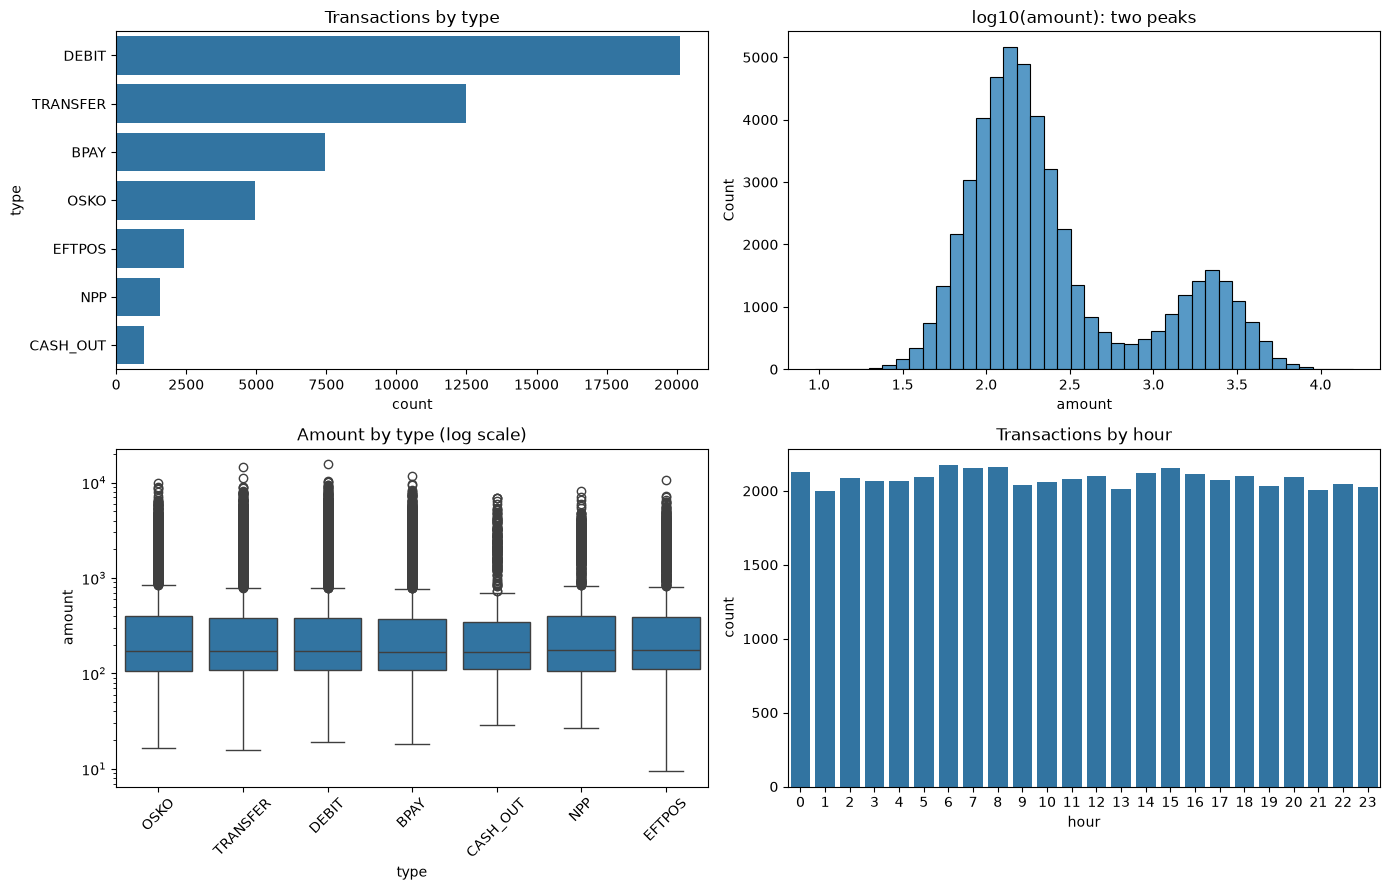

In [13]:
print(data[['amount', 'oldbalanceOrg', 'newbalanceOrig']].describe().round(1))
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(data=data, y='type', order=data['type'].value_counts().index, ax=ax[0, 0]); ax[0, 0].set_title('Transactions by type')
sns.histplot(np.log10(data['amount']), bins=40, ax=ax[0, 1]); ax[0, 1].set_title('log10(amount): two peaks')
sns.boxplot(data=data, x='type', y='amount', ax=ax[1, 0]); ax[1, 0].set_yscale('log'); ax[1, 0].set_title('Amount by type (log scale)')
ax[1, 0].tick_params(axis='x', rotation=45)
sns.countplot(data=data, x='hour', ax=ax[1, 1]); ax[1, 1].set_title('Transactions by hour')
plt.tight_layout(); plt.show()

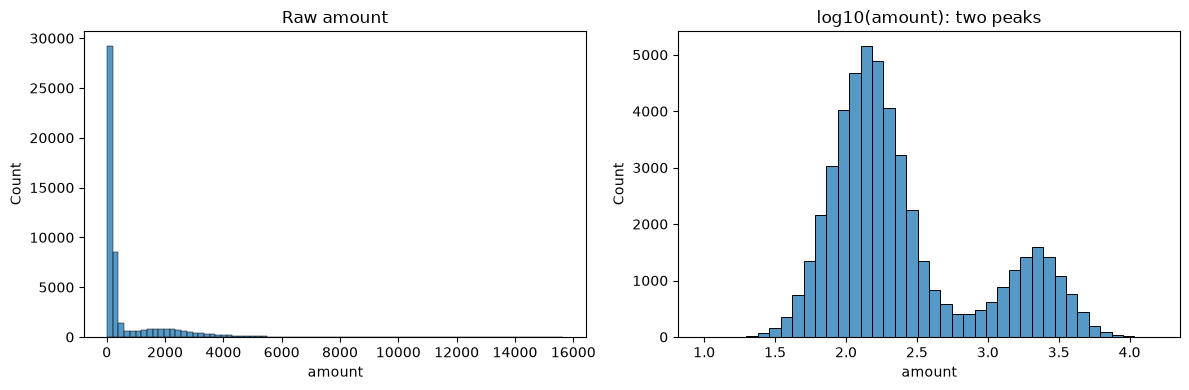

Skewness raw: 2.8 | after log: 0.94
Mean: 633.8 | median: 172.0
% over 1,000: 19.3 | 95th percentile: 3004 | 99th percentile: 4747


In [21]:
a = data['amount']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(a, bins=80, ax=ax[0]); ax[0].set_title('Raw amount')
sns.histplot(np.log10(a), bins=40, ax=ax[1]); ax[1].set_title('log10(amount): two peaks')
plt.tight_layout(); plt.show()

print('Skewness raw:', round(a.skew(), 2), '| after log:', round(np.log1p(a).skew(), 2))
print('Mean:', round(a.mean(), 1), '| median:', round(a.median(), 1))
print('% over 1,000:', round((a > 1000).mean() * 100, 1),
      '| 95th percentile:', round(a.quantile(0.95)), '| 99th percentile:', round(a.quantile(0.99)))

In [22]:
# What makes the second peak? Median amount and share of large payments by category
by_cat = data.groupby('category')['amount'].agg(median='median', share_over_700=lambda x: (x > 700).mean() * 100)
print(by_cat.round(1).sort_values('median'), '\n')

# Does the transaction type change the amount?
print(data.groupby('type')['amount'].median().round(1).sort_values(), '\n')

# Is activity spread over the day?
h = data['hour'].value_counts(normalize=True).sort_index() * 100
print('Share per hour: min', round(h.min(), 1), '% | max', round(h.max(), 1), '%')

               median  share_over_700
category                             
Transport        88.1             0.0
Healthcare      111.1             0.0
Recreation      130.5             0.0
Other           165.1             0.1
Food            166.2             0.1
Utilities       218.7             0.5
Education       546.4            30.5
Housing        2197.9            99.0
Shell Company  4916.1           100.0 

type
CASH_OUT    169.0
BPAY        169.8
DEBIT       171.5
TRANSFER    172.4
OSKO        173.3
NPP         174.7
EFTPOS      174.9
Name: amount, dtype: float64 

Share per hour: min 4.0 % | max 4.4 %


**EDA findings (study notes: rewrite in your own words for the paper)**

1. **Transaction mix.** DEBIT is the most common type (40%), then TRANSFER (25%) and BPAY (15%); CASH_OUT is rare (2%, about 1,000 rows). Rare types give the models few examples, and category-spelling errors will mostly hit the common types.
2. **Amounts are strongly right-skewed** (skewness 2.8; mean 634 vs median 172; 99% under 4,747, maximum 15,658). The mean is misleading, so medians are reported, and amounts are log-transformed for the distance-based models (LOF, One-Class SVM). Large genuine payments may be flagged as anomalies, which would be false positives.
3. **Two groups of transactions.** On a log scale the amounts form two peaks: everyday spending (around 100–200) and larger payments (around 1,700–2,800). The second peak is almost entirely **Housing** (median 2,198; 99% over 700), about 20% of transactions. So a large amount is normal for Housing but unusual for Food, which is why `category` is kept as a feature.
4. **Signs of synthetic data.** Median amounts are almost identical across transaction types (169–175), and transactions are spread evenly across all 24 hours (about 4.2% each, including 3 am). This is a limitation: results may not transfer directly to real data, and time-of-day patterns cannot reveal errors, so the hour/timestamp check feature is needed.
5. **The baseline is clean.** No missing values, duplicates, balance errors, negative values, city/state or hour/timestamp mismatches. Any error in later notebooks is one that was injected, so the labels are exact.

## 7. Save the clean sample

In [23]:
config.PROCESSED.mkdir(parents=True, exist_ok=True)
data.to_csv(config.CLEAN_FILE, index=False)
print('Saved', config.CLEAN_FILE.name, data.shape)

Saved aml_clean_sample.csv (50000, 22)


## 8. Evidence: why the laundering rows were excluded

In [24]:
ml, nm = df[df['isMoneyLaundering'] == 1], df[df['isMoneyLaundering'] == 0]
pd.DataFrame({
    'Normal': [len(nm), nm['amount'].median(), nm['amount'].mean(), (nm['type'] == 'TRANSFER').mean() * 100, (nm['category'] == 'Shell Company').mean() * 100],
    'Laundering': [len(ml), ml['amount'].median(), ml['amount'].mean(), (ml['type'] == 'TRANSFER').mean() * 100, (ml['category'] == 'Shell Company').mean() * 100]},
    index=['Rows', 'Median amount', 'Mean amount', '% TRANSFER', '% Shell Company']).round(1)

,Normal,Laundering
Rows,1088589.0,1411.0
Median amount,172.1,4845.9
Mean amount,636.8,10066.5
% TRANSFER,25.0,95.9
% Shell Company,0.1,8.3


In [26]:
# If we had NOT removed them: how often does a detector flag laundering rows vs normal rows?
from sklearn.ensemble import IsolationForest

s = df.sample(50000, random_state=42)                    # random 50k INCLUDING laundering rows
print('Laundering rows in this sample:', s['isMoneyLaundering'].sum())
X = pd.get_dummies(s[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'hour', 'type', 'category']],
                   columns=['type', 'category']).astype(float)
flag = IsolationForest(contamination=0.05, random_state=42).fit(X).predict(X) == -1
y = s['isMoneyLaundering'].values
print(f'Flagged as anomalies: normal rows {flag[y == 0].mean() * 100:.1f}% | laundering rows {flag[y == 1].mean() * 100:.1f}%')
print('Laundering rows flagged:', flag[y == 1].sum())

Laundering rows in this sample: 64
Flagged as anomalies: normal rows 5.0% | laundering rows 37.5%
Laundering rows flagged: 24


In [27]:
import os
print(os.getcwd())

/Users/priyareddy/Combined_CA_Research/xai-dq-anomaly/notebooks
